In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data

In [2]:
def mostrar(imagens,titulos,cmap='gray',tamanho=4):
  n = len(imagens)
  plt.figure(figsize=(tamanho*n,tamanho))

  for i in range(n):
    plt.subplot(1, n, i+1)
    plt.imshow(imagens[i],cmap=cmap)
    plt.title(titulos[i])
    plt.axis('off')
  plt.show()


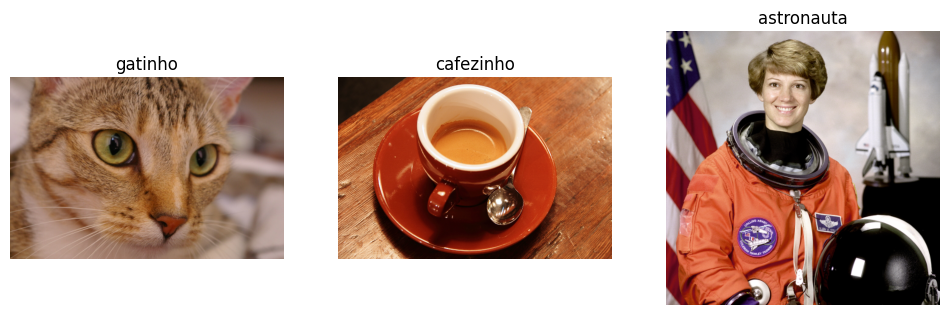

In [3]:
gato = data.cat()
cafe = data.coffee()
astronauta = data.astronaut()

mostrar([gato,cafe,astronauta],["gatinho","cafezinho","astronauta"])


In [4]:
moedas = data.coins()

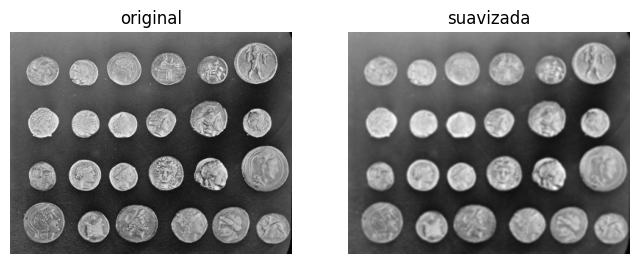

In [5]:
moedas_suave = cv2.GaussianBlur(moedas, (5,5), 0)

mostrar([moedas, moedas_suave], ['original', 'suavizada'])

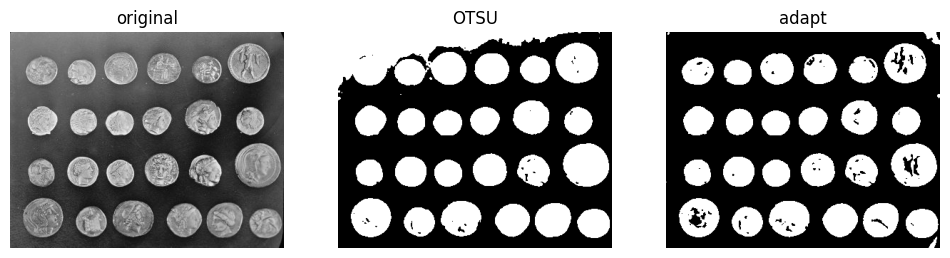

In [6]:
_, moedas_otsu = cv2.threshold(moedas_suave, 0, 255, cv2.THRESH_OTSU)

moedas_adapt = cv2.adaptiveThreshold(moedas_suave, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 101, -10)

mostrar([moedas, moedas_otsu, moedas_adapt], ['original', 'OTSU', 'adapt'])

In [7]:
contornos, _ = cv2.findContours(moedas_adapt, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

In [8]:
contornos = [c for c in contornos if cv2.contourArea(c) > 500]
print(len(contornos))

24


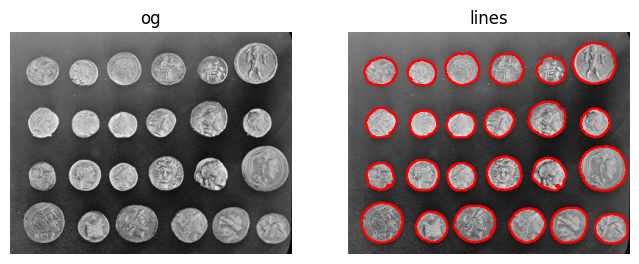

In [9]:
saida = cv2.cvtColor(moedas, cv2.COLOR_GRAY2RGB)

imagen_contours = cv2.drawContours(saida, contornos, -1, (255,0,0), 2)

mostrar([moedas, saida], ['og', 'lines'])

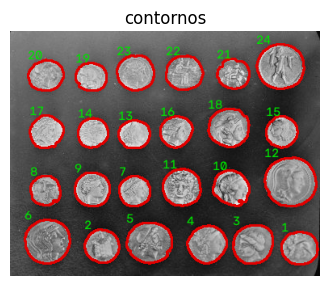

In [13]:
saida = cv2.cvtColor(moedas, cv2.COLOR_GRAY2RGB)
cv2.drawContours(saida, contornos, -1, (225, 0, 0), 2)

for i,c in enumerate(contornos):
  x, y, w, h = cv2.boundingRect(c)
  cv2.putText(saida, str(i+1),(x,y), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 225, 0))

mostrar([saida], ['contornos'])